# Лабораторная работа 2. Классификация. Нейронные сети

## Введение

### Цели и задачи

Цель работы: изучение методов классификации данных, реализованные в библиотеке Scikit-Learn, а также ознакомление с нейронными сетями с использованием библиотек TensorFlow и TensorBoard. 

Постановка задачи:

1. Необходимо выбрать и подготовить датасет для классификации, затем построить классификационные модели с помощью пяти методов:

    a. Наивный Байесовский классификатор (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB);

    b. Деревья решений (Decision Tree);

    c. Линейный дискриминантный анализ (Linear Discriminant Analysis);

    d. Метод опорных векторов (Support Vector Machines);

    e. Метод ближайших соседей (k-Nearest Neighbors);

2. Затем сравните качество работы классификаторов с помощью следующих метрик:

    a. Accuracy (точность),

    b. Precision (доля правильно классифицированных положительных примеров),

    c. Recall (чувствительность, доля верно найденных положительных примеров),

    d. F1-Score (среднее гармоническое precision и recall),

    e. Площадь под кривой ROC (AUC-ROC).

3. Настройте гиперпараметры каждого метода и проведите исследование влияния различных параметров на качество классификации.

4. Реализуйте и протестируйте нейронную сеть на TensorFlow, исследуйте эффект настройки гиперпараметров и визуализируйте процесс обучения с помощью инструмента TensorBoard.

## Выбор и подготовка датасета

### Информация о выбранном датасете

В работе используется датасет Indian Liver Patient Dataset. Это реальные клинические данные 583 пациентов из северо-восточной части штата Андхра-Прадеш (Индия) - результаты лабораторных анализов крови. По результатам анализов крови определить, есть ли у пациента заболевание печени. 



1. `Age` - возраст пациента, лет  
2. `Gender` - пол пациента (Male/Female)   
3. `Total_Bilirubin` - общий билирубин, мг/дл   
4. `Direct_Bilirubin` - прямой (связанный) билирубин, мг/дл   
5. `Alkaline_Phosphotase` - щелочная фосфатаза, ед/л  
6. `Alamine_Aminotransferase` - аланинаминотрансфераза (АЛТ), ед/л  
7. `Aspartate_Aminotransferase` - аспартатаминотрансфераза (АСТ), ед/л   
8. `Total_Protiens` - общий белок, г/дл   
9. `Albumin` - альбумин, г/дл   
10. `Albumin_and_Globulin_Ratio` - отношение альбумина к глобулину   
11. `Dataset` - **целевая переменная**: `1` - заболевание печени, `2` - нет заболевания    
Итого: 10 признаков (9 числовых + пол) и 1 целевая переменная, 583 объекта.

### Импорт библиотек

In [52]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV,
    cross_validate, cross_val_score
)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
    balanced_accuracy_score
)

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

### Загрузка и первичный осмотр данных

In [53]:
df = pd.read_csv('indian_liver_patient.csv')
print('Размер таблицы (строк, столбцов):', df.shape)
df.head(10)

Размер таблицы (строк, столбцов): (583, 11)


,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1
5,46,Male,1.8,0.7,208,19,14,7.6,4.4,1.30,1
6,26,Female,0.9,0.2,154,16,12,7.0,3.5,1.00,1
7,29,Female,0.9,0.3,202,14,11,6.7,3.6,1.10,1
8,17,Male,0.9,0.3,202,22,19,7.4,4.1,1.20,2
9,55,Male,0.7,0.2,290,53,58,6.8,3.4,1.00,1


In [54]:
df.info()
df.describe().T.round(2)

<class 'pandas.DataFrame'>
RangeIndex: 583 entries, 0 to 582
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         583 non-null    int64  
 1   Gender                      583 non-null    str    
 2   Total_Bilirubin             583 non-null    float64
 3   Direct_Bilirubin            583 non-null    float64
 4   Alkaline_Phosphotase        583 non-null    int64  
 5   Alamine_Aminotransferase    583 non-null    int64  
 6   Aspartate_Aminotransferase  583 non-null    int64  
 7   Total_Protiens              583 non-null    float64
 8   Albumin                     583 non-null    float64
 9   Albumin_and_Globulin_Ratio  579 non-null    float64
 10  Dataset                     583 non-null    int64  
dtypes: float64(5), int64(5), str(1)
memory usage: 50.2 KB


,count,mean,std,min,25%,50%,75%,max
Age,583.0,44.75,16.19,4.0,33.0,45.00,58.0,90.0
Total_Bilirubin,583.0,3.30,6.21,0.4,0.8,1.00,2.6,75.0
Direct_Bilirubin,583.0,1.49,2.81,0.1,0.2,0.30,1.3,19.7
Alkaline_Phosphotase,583.0,290.58,242.94,63.0,175.5,208.00,298.0,2110.0
Alamine_Aminotransferase,583.0,80.71,182.62,10.0,23.0,35.00,60.5,2000.0
Aspartate_Aminotransferase,583.0,109.91,288.92,10.0,25.0,42.00,87.0,4929.0
Total_Protiens,583.0,6.48,1.09,2.7,5.8,6.60,7.2,9.6
Albumin,583.0,3.14,0.80,0.9,2.6,3.10,3.8,5.5
Albumin_and_Globulin_Ratio,579.0,0.95,0.32,0.3,0.7,0.93,1.1,2.8
Dataset,583.0,1.29,0.45,1.0,1.0,1.00,2.0,2.0


### Первичный анализ качества данных

In [55]:
df_raw = df.copy()
missing = df_raw.isna().sum().rename('Число пропусков').to_frame()
missing['Доля пропусков, %'] = (df_raw.isna().mean() * 100).round(2)
duplicate_count = int(df_raw.duplicated().sum())
display(missing.sort_values('Число пропусков', ascending=False))
print(f'Полных дубликатов строк: {duplicate_count}')

,Число пропусков,"Доля пропусков, %"
Albumin_and_Globulin_Ratio,4,0.69
Gender,0,0.00
Age,0,0.00
Total_Bilirubin,0,0.00
Direct_Bilirubin,0,0.00
Alamine_Aminotransferase,0,0.00
Alkaline_Phosphotase,0,0.00
Aspartate_Aminotransferase,0,0.00
Total_Protiens,0,0.00
Albumin,0,0.00


Полных дубликатов строк: 13


### Анализ целевой переменной

Распределение исходной целевой переменной Dataset

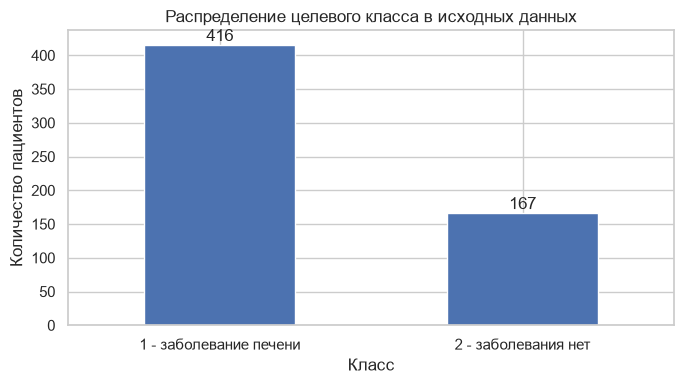

In [56]:
class_counts_raw = df_raw['Dataset'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 4))
labels = {1: '1 - заболевание печени', 2: '2 - заболевания нет'}
plot_counts = class_counts_raw.rename(index=labels)
plot_counts.plot(kind='bar', ax=ax)
ax.set_title('Распределение целевого класса в исходных данных')
ax.set_xlabel('Класс'); ax.set_ylabel('Количество пациентов')
ax.tick_params(axis='x', rotation=0)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom')
plt.tight_layout(); plt.show()

### Распределение признаков

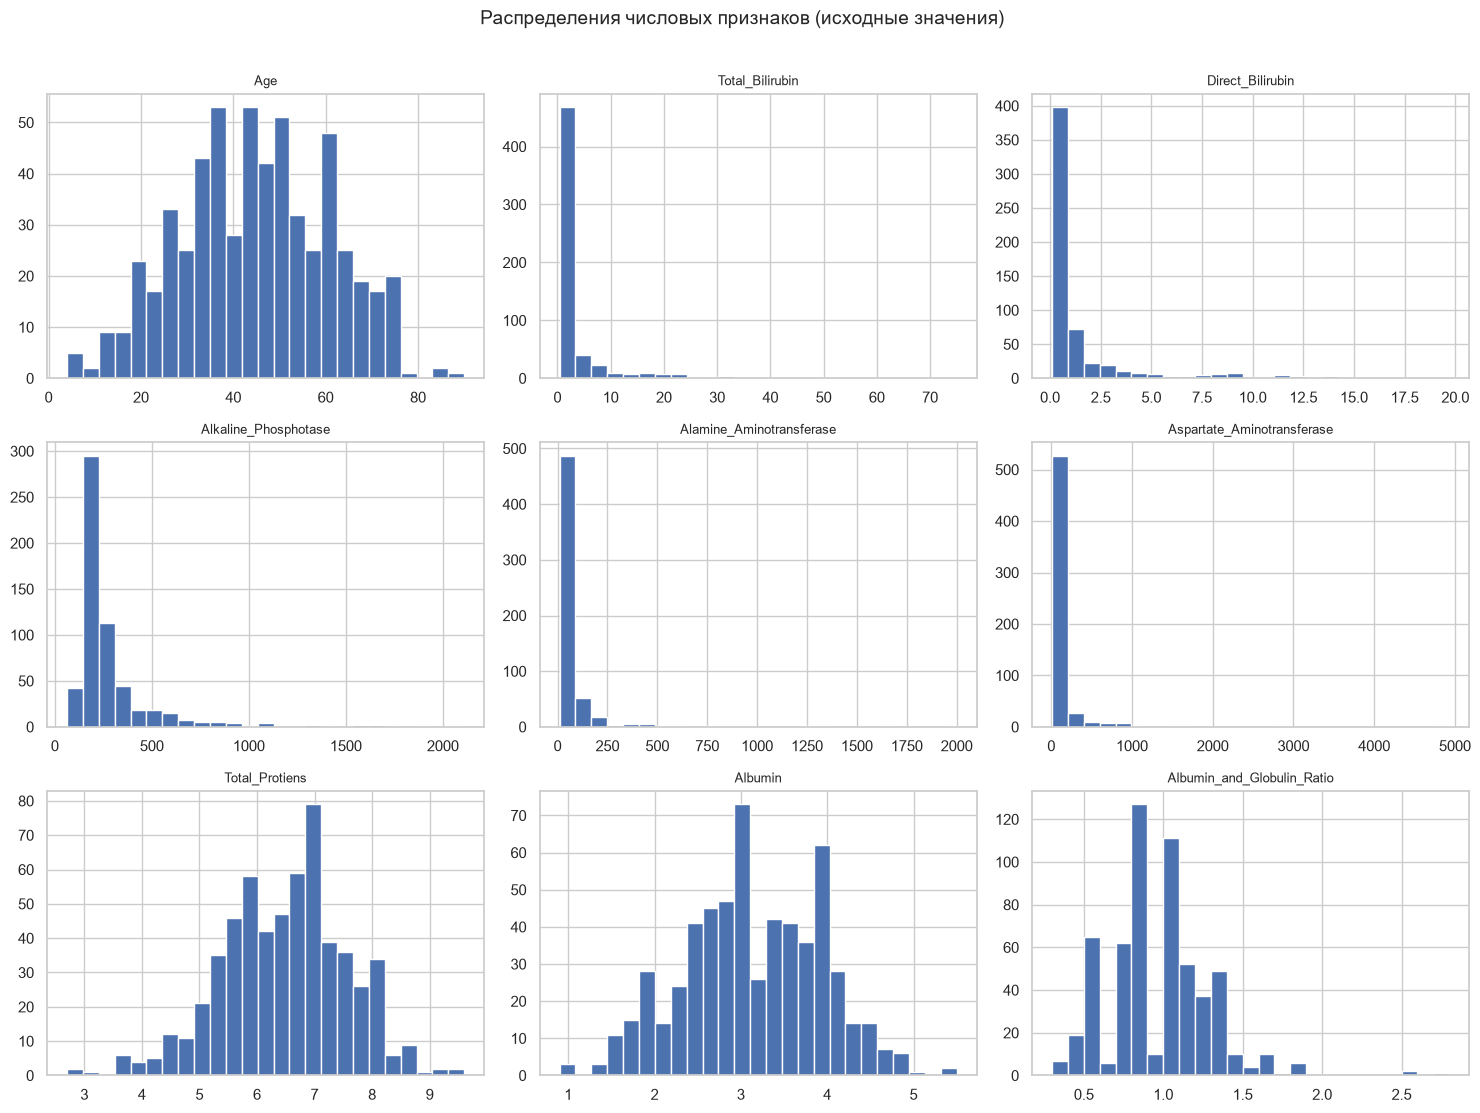

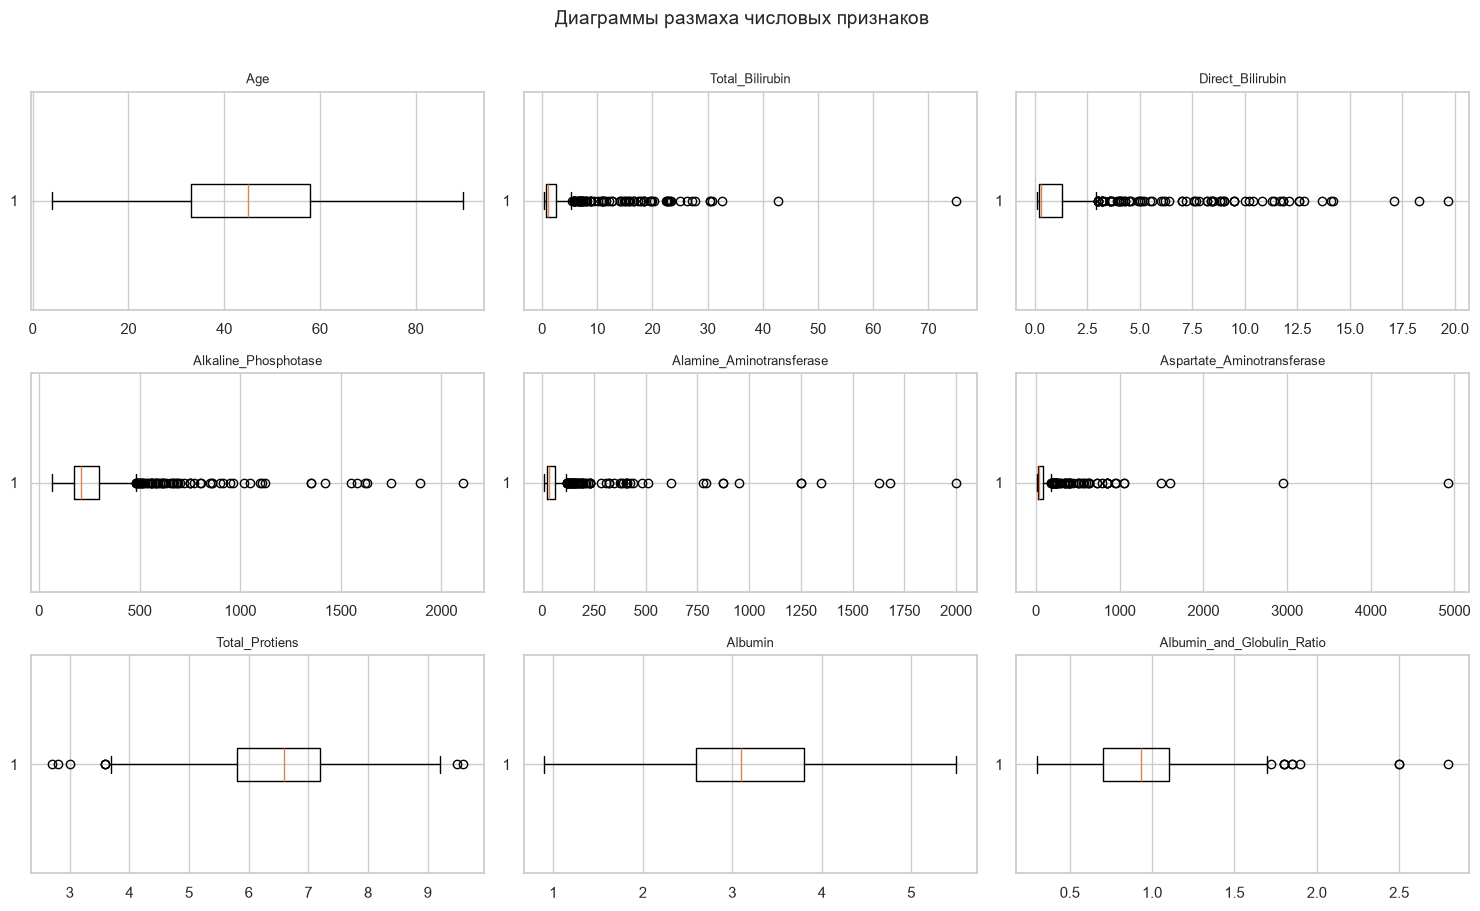

Признаки с наибольшей абсолютной асимметрией распределения:


,Асимметрия
Aspartate_Aminotransferase,10.546177
Alamine_Aminotransferase,6.549192
Total_Bilirubin,4.907474
Alkaline_Phosphotase,3.765106
Direct_Bilirubin,3.212403
Albumin_and_Globulin_Ratio,0.992299


In [57]:
numeric_cols_raw = df_raw.select_dtypes(include=np.number).columns.drop('Dataset', errors='ignore').tolist()
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.flat, numeric_cols_raw):
    ax.hist(df_raw[col].dropna(), bins=25, edgecolor='white')
    ax.set_title(col, fontsize=9)
    ax.set_xlabel('')
for ax in axes.flat[len(numeric_cols_raw):]:
    ax.axis('off')
fig.suptitle('Распределения числовых признаков (исходные значения)', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

# Для компактного сравнения масштабы показаны отдельно на каждом subplot.
fig, axes = plt.subplots(3, 3, figsize=(15, 9))
for ax, col in zip(axes.flat, numeric_cols_raw):
    ax.boxplot(df_raw[col].dropna(), vert=False)
    ax.set_title(col, fontsize=9)
    ax.set_xlabel('')
for ax in axes.flat[len(numeric_cols_raw):]:
    ax.axis('off')
fig.suptitle('Диаграммы размаха числовых признаков', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

skewness = df_raw[numeric_cols_raw].skew(numeric_only=True).sort_values(key=lambda s: s.abs(), ascending=False)
print('Признаки с наибольшей абсолютной асимметрией распределения:')
display(skewness.to_frame('Асимметрия').head(6))

### Предобработка данных

In [58]:
# 1. Удаляем полные дубликаты до разделения на train/test.
n_before = len(df_raw)
data = df_raw.drop_duplicates().reset_index(drop=True).copy()
removed_duplicates = n_before - len(data)

# 1 = заболевание, 0 = заболевания нет.
data['target'] = data['Dataset'].map({1: 1, 2: 0})
if data['target'].isna().any():
    raise ValueError('В Dataset обнаружены неожиданные значения, отличные от 1 и 2.')
data = data.drop(columns='Dataset')

# 3. Кодируем бинарный признак пола: Male=1, Female=0.
unknown_gender = set(data['Gender'].dropna().unique()) - {'Male', 'Female'}
if unknown_gender:
    raise ValueError(f'Неизвестные значения Gender: {unknown_gender}')
data['Gender'] = data['Gender'].map({'Female': 0, 'Male': 1}).astype(float)

X = data.drop(columns='target')
y = data['target'].astype(int)

print(f'Исходных строк: {n_before}')
print(f'Удалено полных дубликатов: {removed_duplicates}')
print(f'Строк после удаления дубликатов: {len(data)}')
print(f'Входных признаков: {X.shape[1]}')
print('Пропуски после удаления дубликатов (будут заполнены в Pipeline):')
display(X.isna().sum().rename('Пропусков').to_frame().query('Пропусков > 0'))
print('Целевой класс после очистки (1 = заболевание; 0 = нет заболевания):')
class_counts = y.value_counts().sort_index()
display(pd.DataFrame({'Количество': class_counts, 'Доля, %': (100*class_counts/len(y)).round(2)}).rename(index={0:'0 — нет заболевания', 1:'1 — заболевание'}))

Исходных строк: 583
Удалено полных дубликатов: 13
Строк после удаления дубликатов: 570
Входных признаков: 10
Пропуски после удаления дубликатов (будут заполнены в Pipeline):


,Пропусков
Albumin_and_Globulin_Ratio,4


Целевой класс после очистки (1 = заболевание; 0 = нет заболевания):


,Количество,"Доля, %"
target,,
0 — нет заболевания,164,28.77
1 — заболевание,406,71.23


## Разбиение выборки

In [76]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

split_summary = pd.DataFrame({
    'Объектов': [len(X_train), len(X_test), len(X)],
    'Заболевание (1)': [int(y_train.sum()), int(y_test.sum()), int(y.sum())],
    'Нет заболевания (0)': [int((y_train == 0).sum()), int((y_test == 0).sum()), int((y == 0).sum())],
    'Доля заболевания, %': [100*y_train.mean(), 100*y_test.mean(), 100*y.mean()],
}, index=['Обучающая выборка', 'Тестовая выборка', 'Всего']).round(2)
display(split_summary)
assert set(X_train.index).isdisjoint(set(X_test.index))

,Объектов,Заболевание (1),Нет заболевания (0),"Доля заболевания, %"
Обучающая выборка,456,325,131,71.27
Тестовая выборка,114,81,33,71.05
Всего,570,406,164,71.23


## Методы классификации 

### Описание методов классификации

### Наивный байесовский классификатор 
Строится на теореме Байеса: $P(y\mid x) \propto P(y)\prod_{j} P(x_j\mid y)$. «Наивность» - допущение, что признаки **условно независимы** при заданном классе. Это резко упрощает оценку параметров (нужны лишь одномерные распределения) и делает метод очень быстрым и устойчивым на малых выборках, но допущение нарушается при коррелированных признаках (у нас: билирубины, АЛТ/АСТ, белок/альбумин).
Варианты различаются предположением о распределении $P(x_j\mid y)$:
- **GaussianNB** - признаки непрерывные и нормальные внутри класса. Гиперпараметр `var_smoothing` - доля максимальной дисперсии, добавляемая ко всем дисперсиям для численной устойчивости (сглаживание). Логичный выбор для наших непрерывных признаков.
- **MultinomialNB** - признаки - неотрицательные «счётчики» (классически частоты слов). Гиперпараметры: `alpha` (сглаживание Лапласа), `fit_prior` (учитывать ли априорные вероятности классов). Требует неотрицательных входов, поэтому признаки масштабируются в [0, 1].
- **ComplementNB** - модификация Multinomial, оценивающая параметры по **дополнению** класса (всем остальным); создана для несбалансированных данных. Гиперпараметры: `alpha`, `norm`.
- **BernoulliNB** - признаки бинарны («есть / нет»); непрерывные значения бинаризуются порогом `binarize`. Гиперпараметры: `alpha`, `binarize`.

### Дерево решений (Decision Tree)
Рекурсивно делит пространство признаков порогами вида «признак ≤ значение», выбирая на каждом шаге разбиение, которое сильнее всего уменьшает **неоднородность** узла (критерии `gini` или `entropy`/`log_loss`). Лист выдаёт долю класса. Метод интерпретируем, не требует масштабирования, умеет ловить нелинейности и взаимодействия, но **склонен к переобучению**: неограниченное дерево запоминает обучающую выборку. Ключевые гиперпараметры: `max_depth`, `min_samples_leaf`, `criterion`, `ccp_alpha` (обрезка по сложности), `class_weight`.

### Линейный дискриминантный анализ (LDA)
Предполагает, что внутри каждого класса признаки имеют нормальное распределение с **общей для классов ковариационной матрицей**. Тогда оптимальная граница по Байесу - **гиперплоскость**; LDA одновременно ищет направление, максимально разделяющее классы (критерий Фишера). Гиперпараметры: `solver` (`svd`, `lsqr`, `eigen`), `shrinkage` (регуляризация ковариационной матрицы - полезна при коррелированных признаках; доступна для `lsqr`/`eigen`; `'auto'` - оценка Ледойта-Вольфа), `priors` (априорные вероятности классов - сдвигают порог).

### Метод опорных векторов (SVM)
Находит разделяющую гиперплоскость с **максимальным зазором** между классами; «мягкий» зазор допускает ошибки со штрафом `C` (большой `C` - меньше ошибок на обучении, но выше риск переобучения). С помощью **ядер** (`linear`, `poly`, `rbf`, `sigmoid`) строится нелинейная граница. У RBF-ядра параметр `gamma` задаёт «радиус влияния» объекта (большая `gamma` - очень локальная, «изрезанная» граница). Метод чувствителен к масштабу признаков. `class_weight='balanced'` увеличивает штраф за ошибки на редком классе.

### Метод ближайших соседей (kNN)
«Ленивый» метод: при предсказании находит `k` ближайших обучающих объектов и голосует (возможно, с весами обратно пропорциональными расстоянию). Гиперпараметры: `n_neighbors` (малое `k` - шумная граница и переобучение, большое - сильное сглаживание и вырождение к большинству), `weights` (`uniform` / `distance`), `metric` (евклидова, манхэттенская, Чебышёва, Минковского). Очень чувствителен к масштабу признаков и «проклятию размерности».

### Метрики качества
Пусть положительный класс - «болен»; TP, FP, TN, FN - число верно/неверно найденных больных и здоровых.
- **Accuracy** = (TP + TN) / (TP + TN + FP + FN) - доля верных ответов; при дисбалансе 71/29 тривиальный ответ «все больны» даёт ≈ 0.71.
- **Precision** = TP / (TP + FP) - если модель сказала «болен», как часто это правда.
- **Recall** = TP / (TP + FN) - какую долю реально больных модель нашла. В медицине пропуск больного (FN) обычно опаснее ложной тревоги, поэтому Recall особенно важен.
- **F1** = 2·Precision·Recall / (Precision + Recall) - гармоническое среднее. Для положительного (преобладающего) класса легко завышается тривиальной моделью (при ответе «все больны» F1 = 0.83).
- **ROC-AUC** - площадь под кривой «TPR от FPR» при всех возможных порогах; вероятность того, что случайный больной получит оценку выше, чем случайный здоровый. 0.5 - случайное угадывание, 1.0 - идеал. Не зависит от порога и дисбаланса.
- Дополнительно в сравнении используется **Specificity** = TN / (TN + FP) - доля верно опознанных здоровых; она показывает, «не отвечает ли» модель всем подряд «болен».

### Обучение модели

In [60]:
def make_pipeline(estimator, scaling='standard'):
    """Импутация обучающей медианой + выбранное масштабирование + модель."""
    steps = [('imputer', SimpleImputer(strategy='median'))]
    if scaling == 'standard':
        steps.append(('scaler', StandardScaler()))
    elif scaling == 'minmax':
        steps.append(('scaler', MinMaxScaler()))
    elif scaling != 'none':
        raise ValueError("scaling должен быть 'standard', 'minmax' или 'none'")
    steps.append(('classifier', estimator))
    return Pipeline(steps)


def get_score(model, X_part):
    """Скор для ROC-AUC: вероятность класса 1 или decision_function."""
    if hasattr(model, 'predict_proba'):
        proba = model.predict_proba(X_part)
        classes = list(model.classes_) if hasattr(model, 'classes_') else None
        if classes is not None and 1 in classes:
            return proba[:, classes.index(1)]
        return proba[:, 1]
    if hasattr(model, 'decision_function'):
        return model.decision_function(X_part)
    return model.predict(X_part)


def calc_metrics(model, X_part, y_true):
    y_pred = model.predict(X_part)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1': f1_score(y_true, y_pred, zero_division=0),
        'AUC': roc_auc_score(y_true, get_score(model, X_part)),
        'Specificity': tn / (tn + fp) if (tn + fp) else 0.0,
        'Balanced Accuracy': balanced_accuracy_score(y_true, y_pred),
    }

In [61]:
baseline_models = {
    'GaussianNB': make_pipeline(GaussianNB(), 'standard'),
    'MultinomialNB': make_pipeline(MultinomialNB(), 'minmax'),
    'ComplementNB': make_pipeline(ComplementNB(), 'minmax'),
    'BernoulliNB': make_pipeline(BernoulliNB(binarize=0.0), 'standard'),
    'Decision Tree': make_pipeline(DecisionTreeClassifier(random_state=SEED), 'none'),
    'LDA': make_pipeline(LinearDiscriminantAnalysis(), 'standard'),
    'SVM (RBF)': make_pipeline(SVC(probability=True, random_state=SEED), 'standard'),
    'kNN': make_pipeline(KNeighborsClassifier(), 'standard'),
}

baseline_rows = {}
fitted_base = {}
for name, model in baseline_models.items():
    model.fit(X_train, y_train)
    fitted_base[name] = model
    row = calc_metrics(model, X_test, y_test)
    row['Train Accuracy'] = accuracy_score(y_train, model.predict(X_train))
    baseline_rows[name] = row
baseline_df = pd.DataFrame(baseline_rows).T.sort_values('F1', ascending=False)
print('Метрики базовых моделей на тестовой выборке (не участвовавшей в обучении):')
display(baseline_df.round(3))
print('\nЛучшая базовая модель по F1 положительного класса:', baseline_df['F1'].idxmax())
print('Лучшая базовая модель по ROC-AUC:', baseline_df['AUC'].idxmax())

Метрики базовых моделей на тестовой выборке (не участвовавшей в обучении):


,Accuracy,Precision,Recall,F1,AUC,Specificity,Balanced Accuracy,Train Accuracy
MultinomialNB,0.711,0.711,1.000,0.831,0.804,0.000,0.500,0.713
SVM (RBF),0.711,0.711,1.000,0.831,0.654,0.000,0.500,0.713
LDA,0.702,0.720,0.951,0.819,0.765,0.091,0.521,0.711
kNN,0.693,0.745,0.864,0.800,0.681,0.273,0.568,0.792
BernoulliNB,0.719,0.818,0.778,0.797,0.798,0.576,0.677,0.658
ComplementNB,0.693,0.960,0.593,0.733,0.804,0.939,0.766,0.581
Decision Tree,0.623,0.744,0.716,0.730,0.555,0.394,0.555,1.000
GaussianNB,0.605,1.000,0.444,0.615,0.808,1.000,0.722,0.533



Лучшая базовая модель по F1 положительного класса: MultinomialNB
Лучшая базовая модель по ROC-AUC: GaussianNB


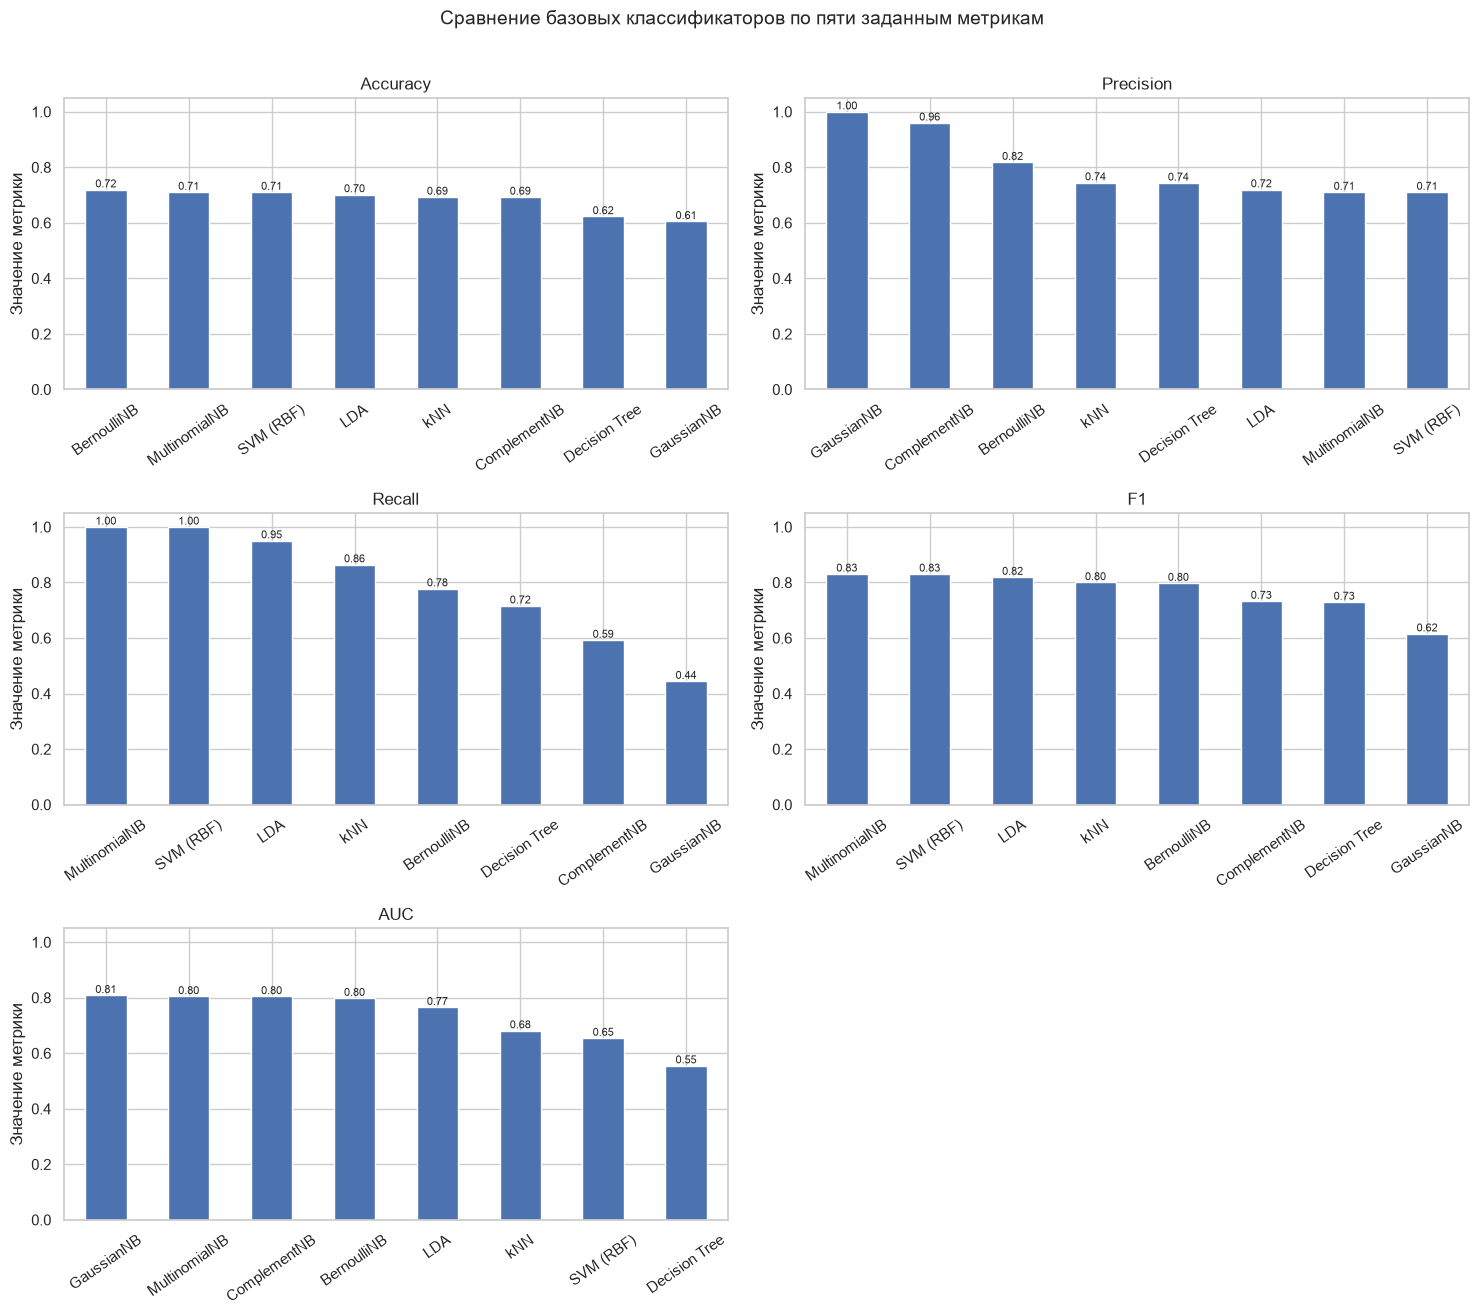

Лидеры по каждой метрике:
  Accuracy: BernoulliNB = 0.719
  Precision: GaussianNB = 1.000
  Recall: MultinomialNB = 1.000
  F1: MultinomialNB = 0.831
  AUC: GaussianNB = 0.808


In [62]:
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']
fig, axes = plt.subplots(3, 2, figsize=(15, 13))
for ax, metric in zip(axes.flat, metrics_to_plot):
    values = baseline_df[metric].sort_values(ascending=False)
    values.plot(kind='bar', ax=ax)
    ax.set_title(metric)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('Значение метрики')
    ax.tick_params(axis='x', rotation=35)
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.2f}', (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom', fontsize=8)
axes.flat[-1].axis('off')
fig.suptitle('Сравнение базовых классификаторов по пяти заданным метрикам', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

print('Лидеры по каждой метрике:')
for metric in metrics_to_plot:
    best_name = baseline_df[metric].idxmax()
    print(f'  {metric}: {best_name} = {baseline_df.loc[best_name, metric]:.3f}')

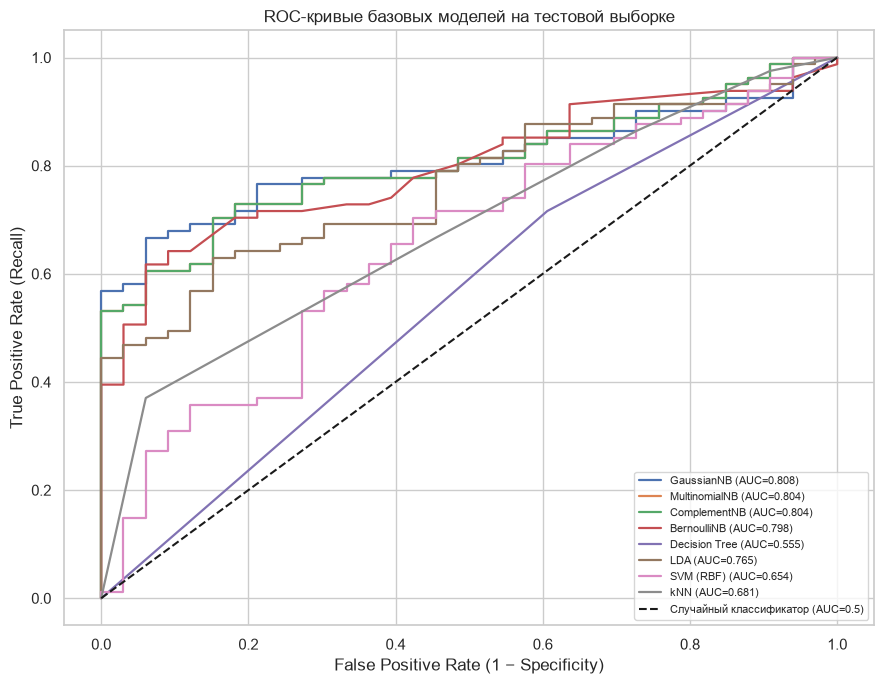

Максимальный AUC среди базовых моделей: 0.808 — GaussianNB


In [63]:
plt.figure(figsize=(9, 7))
for name, model in fitted_base.items():
    fpr, tpr, _ = roc_curve(y_test, get_score(model, X_test))
    plt.plot(fpr, tpr, linewidth=1.6, label=f'{name} (AUC={baseline_df.loc[name, "AUC"]:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Случайный классификатор (AUC=0.5)')
plt.xlabel('False Positive Rate (1 − Specificity)')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC-кривые базовых моделей на тестовой выборке')
plt.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()
print('Максимальный AUC среди базовых моделей:', f'{baseline_df.AUC.max():.3f}', '—', baseline_df.AUC.idxmax())

## Настройка гиперпараметров

In [64]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
tuned_models = {}
tuned_rows = {}
search_summaries = []


def clean_params(params):
    """Очищает параметры от системных оберток numpy для читаемого вывода"""
    clean = {}
    for k, v in params.items():
        if isinstance(v, np.ndarray):
            clean[k] = v.tolist()
        elif isinstance(v, (np.floating, np.integer)):
            clean[k] = v.item()
        else:
            clean[k] = v
    return clean


def plot_sweep(df_sweep, x_col, title, log_x=False):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for metric in ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']:
        ax.plot(df_sweep[x_col], df_sweep[metric], marker='o', label=metric)
    ax.set_xlabel(x_col)
    ax.set_ylabel('Метрика на тесте')
    ax.set_title(title)
    ax.set_ylim(0, 1.05)
    ax.legend(loc='best', fontsize=8)
    if log_x:
        ax.set_xscale('log')
    plt.tight_layout()
    plt.show()


def sweep_and_plot(name, values, factory, scaling, param_label, log_x=False):
    rows = []
    for v in values:
        model = make_pipeline(factory(v), scaling)
        model.fit(X_train, y_train)
        m = calc_metrics(model, X_test, y_test)
        m[param_label] = v
        m['_x'] = str(v)
        m['CV AUC'] = cross_val_score(
            make_pipeline(factory(v), scaling), X_train, y_train,
            cv=cv, scoring='roc_auc'
        ).mean()
        rows.append(m)
    
    df_sweep = pd.DataFrame(rows)
    
    numeric_ok = all(isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, bool) for v in values)
    if numeric_ok and not any(v is None for v in values):
        plot_sweep(df_sweep, param_label, f'{name}: влияние {param_label}', log_x=log_x)
    else:
        fig, ax = plt.subplots(figsize=(8, 4.5))
        x = np.arange(len(df_sweep))
        for metric in ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']:
            ax.plot(x, df_sweep[metric], marker='o', label=metric)
        ax.set_xticks(x, df_sweep['_x'], rotation=30)
        ax.set_xlabel(param_label)
        ax.set_ylabel('Метрика на тесте')
        ax.set_title(f'{name}: влияние {param_label}')
        ax.set_ylim(0, 1.05)
        ax.legend(loc='best', fontsize=8)
        plt.tight_layout()
        plt.show()

    # Вывод таблицы перебора параметров
    print(f"\nРезультаты перебора {param_label}:")
    show = df_sweep[[param_label, 'Accuracy', 'Precision', 'Recall', 'F1', 'AUC', 'CV AUC']].copy()
    print(show.to_string(index=False, formatters={c: (lambda x: f'{x:.3f}') for c in ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC', 'CV AUC']}))
    
    # Вывод лучшего результата
    best_idx = df_sweep['AUC'].idxmax()
    print(f"Лучший {param_label} по AUC: {df_sweep.loc[best_idx, param_label]} "
          f"(AUC: {df_sweep.loc[best_idx, 'AUC']:.3f}, F1: {df_sweep.loc[best_idx, 'F1']:.3f})")
    print("-" * 60)
    
    return df_sweep


def run_grid(name, pipeline, param_grid, scaling_comment=''):
    gs = GridSearchCV(
        pipeline, param_grid, scoring='roc_auc', cv=cv,
        n_jobs=-1, refit=True, return_train_score=True
    )
    gs.fit(X_train, y_train)
    best = gs.best_estimator_
    test_m = calc_metrics(best, X_test, y_test)
    test_m['Train Accuracy'] = accuracy_score(y_train, best.predict(X_train))
    test_m['CV AUC (best)'] = gs.best_score_
    
    tuned_models[name] = best
    tuned_rows[name] = test_m
    search_summaries.append({
        'Модель': name,
        'Лучшие параметры': gs.best_params_,
        'CV AUC': gs.best_score_,
        'Test AUC': test_m['AUC'],
        'Test F1': test_m['F1'],
        'Test Accuracy': test_m['Accuracy'],
    })
    
    print(f"Модель: {name}")
    print(f"Лучшие параметры: {clean_params(gs.best_params_)}")
    print(f"CV ROC-AUC (train): {gs.best_score_:.3f}")
    
    if scaling_comment:
        print(f"Комментарий: {scaling_comment}")
        
    print("\nМетрики лучшей конфигурации на ТЕСТЕ:")
    
    # Превращаем вертикальный список в горизонтальную таблицу (1 строка)
    df_test = pd.DataFrame([test_m])
    # Применяем форматирование только к числовым колонкам
    formatters = {c: (lambda x: f'{x:.3f}') for c in df_test.columns if pd.api.types.is_numeric_dtype(df_test[c])}
    
    # В Jupyter Notebook это выведет красивую горизонтальную таблицу без индекса
    display(df_test.style.format(formatters).hide(axis='index'))
    
    return gs

### GaussianNB  

**Изменяемые параметры**

- `var_smoothing` — доля максимальной дисперсии признаков, которая добавляется ко всем дисперсиям. Это сглаживание: слишком маленькое значение делает оценку неустойчивой на редких хвостах, слишком большое — размывает различия между классами (модель ближе к «всему одинаковая дисперсия»).

Ниже: одномерный перебор `var_smoothing` и `GridSearchCV` по той же сетке.



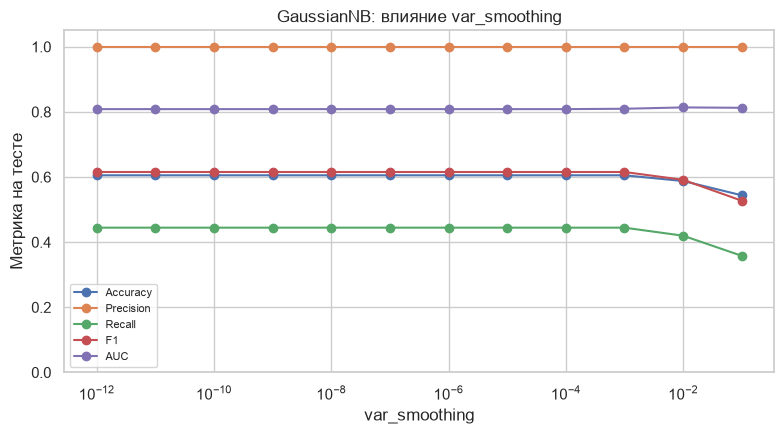


Результаты перебора var_smoothing:
 var_smoothing Accuracy Precision Recall    F1   AUC CV AUC
  1.000000e-12    0.605     1.000  0.444 0.615 0.808  0.713
  1.000000e-11    0.605     1.000  0.444 0.615 0.808  0.713
  1.000000e-10    0.605     1.000  0.444 0.615 0.808  0.713
  1.000000e-09    0.605     1.000  0.444 0.615 0.808  0.713
  1.000000e-08    0.605     1.000  0.444 0.615 0.808  0.713
  1.000000e-07    0.605     1.000  0.444 0.615 0.808  0.713
  1.000000e-06    0.605     1.000  0.444 0.615 0.808  0.713
  1.000000e-05    0.605     1.000  0.444 0.615 0.808  0.713
  1.000000e-04    0.605     1.000  0.444 0.615 0.808  0.713
  1.000000e-03    0.605     1.000  0.444 0.615 0.810  0.714
  1.000000e-02    0.588     1.000  0.420 0.591 0.814  0.715
  1.000000e-01    0.544     1.000  0.358 0.527 0.813  0.713
Лучший var_smoothing по AUC: 0.01 (AUC: 0.814, F1: 0.591)
------------------------------------------------------------
Модель: GaussianNB
Лучшие параметры: {'classifier__var_smoothing'

Accuracy,Precision,Recall,F1,AUC,Specificity,Balanced Accuracy,Train Accuracy,CV AUC (best)
0.588,1.000,0.420,0.591,0.814,1.000,0.710,0.518,0.715


In [65]:
_ = sweep_and_plot(
    'GaussianNB',
    values=np.logspace(-12, -1, 12),
    factory=lambda v: GaussianNB(var_smoothing=v),
    scaling='standard',
    param_label='var_smoothing',
    log_x=True,
)

gs_gnb = run_grid(
    'GaussianNB',
    make_pipeline(GaussianNB(), 'standard'),
    {'classifier__var_smoothing': np.logspace(-12, -1, 12)}
)


### MultinomialNB

**Изменяемые параметры**

- `alpha` — аддитивное сглаживание Лапласа/Лидстоуна. `alpha=0` запрещён при нулевых частотах; рост `alpha` сглаживает оценку $P(x_j|y)$ к равномерной и уменьшает переобучение, но может стереть слабый сигнал.
- `fit_prior` — оценивать ли $P(y)$ по частотам классов. При `False` берутся равные априорные, что частично компенсирует дисбаланс.
- Входы должны быть ≥ 0, поэтому `MinMaxScaler` в [0, 1]. Это **не** классическая постановка для multinomial (там счётчики), но лабораторная требует сравнить все четыре NB.


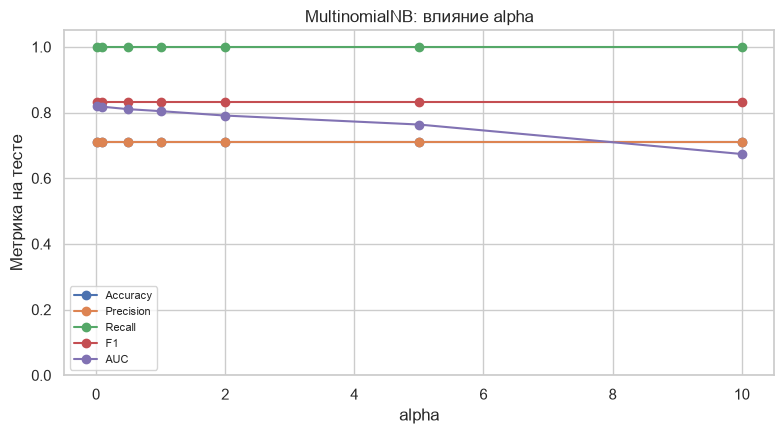


Результаты перебора alpha:
 alpha Accuracy Precision Recall    F1   AUC CV AUC
  0.01    0.711     0.711  1.000 0.831 0.819  0.710
  0.10    0.711     0.711  1.000 0.831 0.818  0.709
  0.50    0.711     0.711  1.000 0.831 0.810  0.706
  1.00    0.711     0.711  1.000 0.831 0.804  0.703
  2.00    0.711     0.711  1.000 0.831 0.791  0.703
  5.00    0.711     0.711  1.000 0.831 0.764  0.678
 10.00    0.711     0.711  1.000 0.831 0.674  0.623
Лучший alpha по AUC: 0.01 (AUC: 0.819, F1: 0.831)
------------------------------------------------------------
Модель: MultinomialNB
Лучшие параметры: {'classifier__alpha': 0.01, 'classifier__fit_prior': True}
CV ROC-AUC (train): 0.710

Метрики лучшей конфигурации на ТЕСТЕ:


Accuracy,Precision,Recall,F1,AUC,Specificity,Balanced Accuracy,Train Accuracy,CV AUC (best)
0.711,0.711,1.000,0.831,0.819,0.000,0.500,0.713,0.710


In [66]:
_ = sweep_and_plot(
    'MultinomialNB',
    values=[0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0],
    factory=lambda v: MultinomialNB(alpha=v),
    scaling='minmax',
    param_label='alpha',
)

gs_mnb = run_grid(
    'MultinomialNB',
    make_pipeline(MultinomialNB(), 'minmax'),
    {
        'classifier__alpha': [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0],
        'classifier__fit_prior': [True, False],
    }
)


### ComplementNB

**Изменяемые параметры**

- `alpha` — сглаживание, как у MultinomialNB.
- `norm` — дополнительная нормализация весов. Авторы метода предлагали её для сильного дисбаланса.
- `fit_prior` — априор классов.

ComplementNB учит веса по **дополнению** класса, поэтому на несбалансированном ILPD он часто лучше отделяет меньшинство (здоровых), чем обычный MultinomialNB — ценой accuracy.


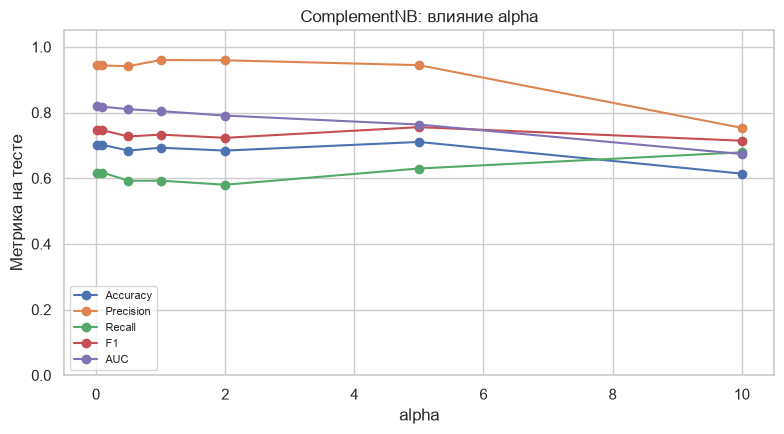


Результаты перебора alpha:
 alpha Accuracy Precision Recall    F1   AUC CV AUC
  0.01    0.702     0.943  0.617 0.746 0.819  0.710
  0.10    0.702     0.943  0.617 0.746 0.818  0.709
  0.50    0.684     0.941  0.593 0.727 0.810  0.706
  1.00    0.693     0.960  0.593 0.733 0.804  0.703
  2.00    0.684     0.959  0.580 0.723 0.791  0.703
  5.00    0.711     0.944  0.630 0.756 0.764  0.678
 10.00    0.614     0.753  0.679 0.714 0.674  0.623
Лучший alpha по AUC: 0.01 (AUC: 0.819, F1: 0.746)
------------------------------------------------------------
Модель: ComplementNB
Лучшие параметры: {'classifier__alpha': 0.01, 'classifier__fit_prior': True, 'classifier__norm': False}
CV ROC-AUC (train): 0.710

Метрики лучшей конфигурации на ТЕСТЕ:


Accuracy,Precision,Recall,F1,AUC,Specificity,Balanced Accuracy,Train Accuracy,CV AUC (best)
0.702,0.943,0.617,0.746,0.819,0.909,0.763,0.599,0.710


In [67]:
_ = sweep_and_plot(
    'ComplementNB',
    values=[0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0],
    factory=lambda v: ComplementNB(alpha=v),
    scaling='minmax',
    param_label='alpha',
)

gs_cnb = run_grid(
    'ComplementNB',
    make_pipeline(ComplementNB(), 'minmax'),
    {
        'classifier__alpha': [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0],
        'classifier__norm': [False, True],
        'classifier__fit_prior': [True, False],
    }
)


### BernoulliNB

**Изменяемые параметры**

- `binarize` — порог: значение признака после `StandardScaler` превращается в 1, если оно > порога, иначе 0. `binarize=0` означает «выше среднего по train» (после стандартизации среднее = 0). Большой порог оставляет единицами только экстремально высокие анализы.
- `alpha` — сглаживание бернуллиевских вероятностей.
- `fit_prior` — априор классов.

Непрерывные анализы грубо режутся на «норма / повышено». Это потеря информации, но медицински осмысленно: клиницист тоже часто смотрит, превышен ли референс.


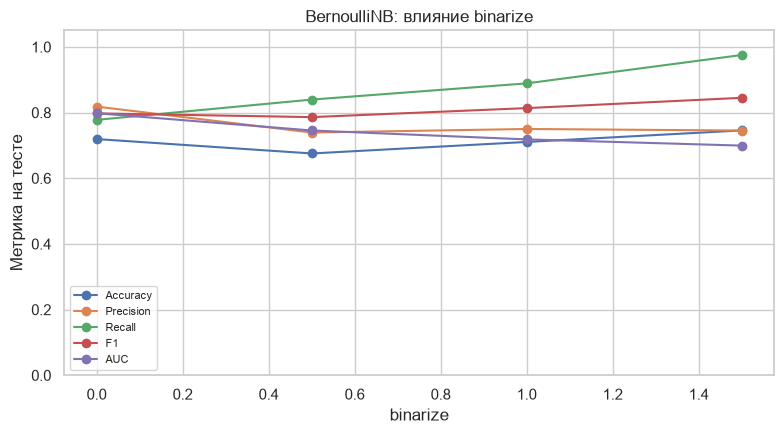


Результаты перебора binarize:
 binarize Accuracy Precision Recall    F1   AUC CV AUC
      0.0    0.719     0.818  0.778 0.797 0.798  0.707
      0.5    0.675     0.739  0.840 0.786 0.745  0.701
      1.0    0.711     0.750  0.889 0.814 0.718  0.608
      1.5    0.746     0.745  0.975 0.845 0.699  0.599
Лучший binarize по AUC: 0.0 (AUC: 0.798, F1: 0.797)
------------------------------------------------------------
Модель: BernoulliNB
Лучшие параметры: {'classifier__alpha': 1.0, 'classifier__binarize': 0.0, 'classifier__fit_prior': True}
CV ROC-AUC (train): 0.707
Комментарий: Слишком высокий binarize оставляет мало «единиц» — модель недополучает сигнал. Слишком низкий делает почти все признаки единицами и стирает различия.

Метрики лучшей конфигурации на ТЕСТЕ:


Accuracy,Precision,Recall,F1,AUC,Specificity,Balanced Accuracy,Train Accuracy,CV AUC (best)
0.719,0.818,0.778,0.797,0.798,0.576,0.677,0.658,0.707


In [68]:
_ = sweep_and_plot(
    'BernoulliNB',
    values=[0.0, 0.5, 1.0, 1.5],
    factory=lambda v: BernoulliNB(binarize=v),
    scaling='standard',
    param_label='binarize',
)

gs_bnb = run_grid(
    'BernoulliNB',
    make_pipeline(BernoulliNB(), 'standard'),
    {
        'classifier__alpha': [0.1, 0.5, 1.0, 2.0, 5.0],
        'classifier__binarize': [0.0, 0.5, 1.0, 1.5],
        'classifier__fit_prior': [True, False],
    },
    scaling_comment='Слишком высокий binarize оставляет мало «единиц» — модель недополучает сигнал. '
                    'Слишком низкий делает почти все признаки единицами и стирает различия.'
)


### Decision Tree

**Изменяемые параметры**

- `max_depth` — максимальная глубина. `None` — дерево растёт до чистых листьев (сильное переобучение на 400+ объектах).
- `min_samples_leaf` — минимальный размер листа; увеличение сглаживает модель.
- `criterion` — `gini` или `entropy` (прирост информации).
- `ccp_alpha` — cost-complexity pruning: чем больше, тем сильнее обрезка.
- `class_weight` — `balanced` увеличивает штраф за ошибки на здоровых (редкий класс 0).

Масштабирование не используем: пороги дерева инвариантны к монотонному масштабу.



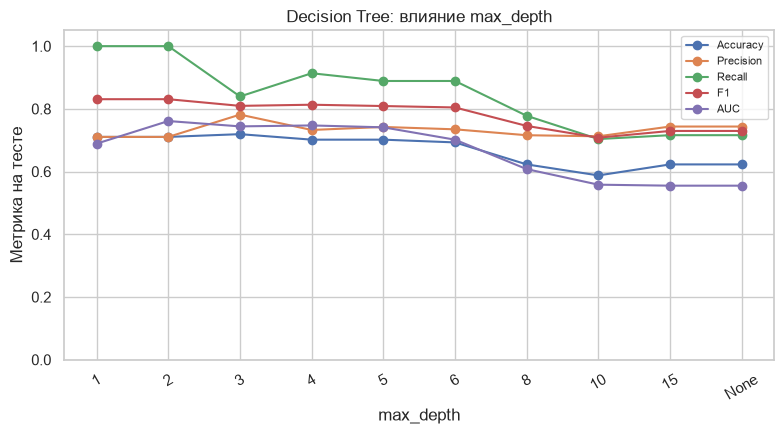


Результаты перебора max_depth:
 max_depth Accuracy Precision Recall    F1   AUC CV AUC
       1.0    0.711     0.711  1.000 0.831 0.689  0.658
       2.0    0.711     0.711  1.000 0.831 0.761  0.674
       3.0    0.719     0.782  0.840 0.810 0.744  0.666
       4.0    0.702     0.733  0.914 0.813 0.747  0.662
       5.0    0.702     0.742  0.889 0.809 0.741  0.651
       6.0    0.693     0.735  0.889 0.804 0.702  0.607
       8.0    0.623     0.716  0.778 0.746 0.608  0.578
      10.0    0.588     0.713  0.704 0.708 0.558  0.586
      15.0    0.623     0.744  0.716 0.730 0.555  0.560
       NaN    0.623     0.744  0.716 0.730 0.555  0.558
Лучший max_depth по AUC: 2.0 (AUC: 0.761, F1: 0.831)
------------------------------------------------------------
Модель: Decision Tree
Лучшие параметры: {'classifier__ccp_alpha': 0.0, 'classifier__class_weight': 'balanced', 'classifier__criterion': 'entropy', 'classifier__max_depth': 4, 'classifier__min_samples_leaf': 20}
CV ROC-AUC (train): 0.705



Accuracy,Precision,Recall,F1,AUC,Specificity,Balanced Accuracy,Train Accuracy,CV AUC (best)
0.684,0.869,0.654,0.746,0.740,0.758,0.706,0.651,0.705


In [69]:
_ = sweep_and_plot(
    'Decision Tree',
    values=[1, 2, 3, 4, 5, 6, 8, 10, 15, None],
    factory=lambda v: DecisionTreeClassifier(max_depth=v, random_state=SEED),
    scaling='none',
    param_label='max_depth',
)

gs_dt = run_grid(
    'Decision Tree',
    make_pipeline(DecisionTreeClassifier(random_state=SEED), 'none'),
    {
        'classifier__max_depth': [2, 3, 4, 5, 7, 10, None],
        'classifier__min_samples_leaf': [1, 5, 10, 20],
        'classifier__criterion': ['gini', 'entropy'],
        'classifier__class_weight': [None, 'balanced'],
        'classifier__ccp_alpha': [0.0, 0.001, 0.01],
    }
)


Фактическая глубина лучшего дерева: 4
Число листьев: 11
Важность признаков (Gini / entropy importance):


,importance
Direct_Bilirubin,0.480
Age,0.237
Alkaline_Phosphotase,0.146
Aspartate_Aminotransferase,0.053
Total_Protiens,0.043
Albumin_and_Globulin_Ratio,0.040
Gender,0.000
Total_Bilirubin,0.000
Alamine_Aminotransferase,0.000
Albumin,0.000


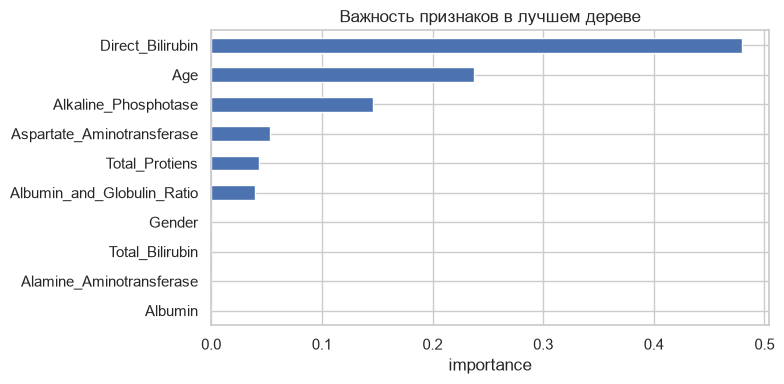

In [70]:
dt_best = tuned_models['Decision Tree'].named_steps['classifier']
print('Фактическая глубина лучшего дерева:', dt_best.get_depth())
print('Число листьев:', dt_best.get_n_leaves())
print('Важность признаков (Gini / entropy importance):')
imp = pd.Series(dt_best.feature_importances_, index=X.columns).sort_values(ascending=False)
display(imp.to_frame('importance').round(3))
fig, ax = plt.subplots(figsize=(8, 4))
imp.plot(kind='barh', ax=ax)
ax.invert_yaxis()
ax.set_title('Важность признаков в лучшем дереве')
ax.set_xlabel('importance')
plt.tight_layout()
plt.show()


### Linear Discriminant Analysis

**Изменяемые параметры**

- `solver`: `svd` (по умолчанию, shrinkage недоступен), `lsqr`, `eigen`.
- `shrinkage`: `None`, `'auto'` (Ledoit–Wolf) или число в (0, 1]. Сжимает оценку ковариации к диагональной — полезно при коррелированных билирубинах/трансаминазах и небольшой выборке.
- `priors`: эмпирические (по умолчанию) или равные `[0.5, 0.5]`. Равные priors сдвигают порог в сторону редкого класса.

Сетка задана списком словарей, потому что `shrinkage` нельзя включать вместе с `svd`.


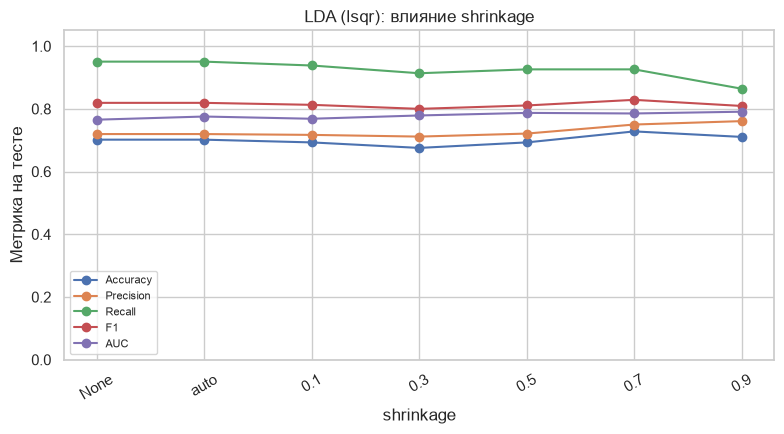


Результаты перебора shrinkage:
shrinkage Accuracy Precision Recall    F1   AUC CV AUC
     None    0.702     0.720  0.951 0.819 0.765  0.679
     auto    0.702     0.720  0.951 0.819 0.776  0.690
      0.1    0.693     0.717  0.938 0.813 0.768  0.687
      0.3    0.675     0.712  0.914 0.800 0.779  0.692
      0.5    0.693     0.721  0.926 0.811 0.787  0.694
      0.7    0.728     0.750  0.926 0.829 0.785  0.701
      0.9    0.711     0.761  0.864 0.809 0.791  0.700
Лучший shrinkage по AUC: 0.9 (AUC: 0.791, F1: 0.809)
------------------------------------------------------------
Модель: LDA
Лучшие параметры: {'classifier__priors': [0.5, 0.5], 'classifier__shrinkage': 'auto', 'classifier__solver': 'lsqr'}
CV ROC-AUC (train): 0.702

Метрики лучшей конфигурации на ТЕСТЕ:


Accuracy,Precision,Recall,F1,AUC,Specificity,Balanced Accuracy,Train Accuracy,CV AUC (best)
0.719,0.902,0.679,0.775,0.783,0.818,0.749,0.638,0.702


In [71]:
# Влияние shrinkage при solver=lsqr
_ = sweep_and_plot(
    'LDA (lsqr)',
    values=[None, 'auto', 0.1, 0.3, 0.5, 0.7, 0.9],
    factory=lambda v: LinearDiscriminantAnalysis(solver='lsqr', shrinkage=v),
    scaling='standard',
    param_label='shrinkage',
)

gs_lda = run_grid(
    'LDA',
    make_pipeline(LinearDiscriminantAnalysis(), 'standard'),
    [
        {'classifier__solver': ['svd'], 'classifier__priors': [None, [0.5, 0.5]]},
        {
            'classifier__solver': ['lsqr', 'eigen'],
            'classifier__shrinkage': [None, 'auto', 0.1, 0.5, 0.9],
            'classifier__priors': [None, [0.5, 0.5]],
        },
    ]
)


### Support Vector Machines

**Изменяемые параметры**

- `kernel`: `linear` (гиперплоскость) vs `rbf` (нелинейное ядро Гаусса).
- `C` — штраф за нарушения зазора. Малый `C` — широкая полоса, больше ошибок на train, лучше обобщение; большой `C` — подгонка под выбросы лабораторных хвостов.
- `gamma` (для RBF): `scale` или явные значения. Большая `gamma` делает границу локальной.
- `class_weight`: `None` или `balanced`.


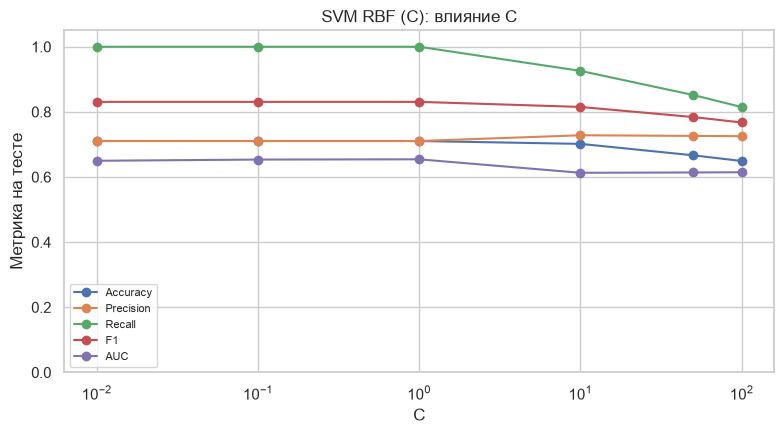


Результаты перебора C:
     C Accuracy Precision Recall    F1   AUC CV AUC
  0.01    0.711     0.711  1.000 0.831 0.650  0.638
  0.10    0.711     0.711  1.000 0.831 0.654  0.638
  1.00    0.711     0.711  1.000 0.831 0.654  0.640
 10.00    0.702     0.728  0.926 0.815 0.613  0.647
 50.00    0.667     0.726  0.852 0.784 0.614  0.667
100.00    0.649     0.725  0.815 0.767 0.615  0.665
Лучший C по AUC: 1.0 (AUC: 0.654, F1: 0.831)
------------------------------------------------------------
Модель: SVM
Лучшие параметры: {'classifier__C': 0.1, 'classifier__class_weight': 'balanced', 'classifier__gamma': 'scale', 'classifier__kernel': 'linear'}
CV ROC-AUC (train): 0.732

Метрики лучшей конфигурации на ТЕСТЕ:


Accuracy,Precision,Recall,F1,AUC,Specificity,Balanced Accuracy,Train Accuracy,CV AUC (best)
0.719,0.980,0.617,0.758,0.816,0.970,0.793,0.581,0.732


In [72]:
_ = sweep_and_plot(
    'SVM RBF (C)',
    values=[0.01, 0.1, 1, 10, 50, 100],
    factory=lambda v: SVC(C=v, kernel='rbf', probability=True, random_state=SEED),
    scaling='standard',
    param_label='C',
    log_x=True,
)

gs_svm = run_grid(
    'SVM',
    make_pipeline(SVC(probability=True, random_state=SEED), 'standard'),
    {
        'classifier__kernel': ['linear', 'rbf'],
        'classifier__C': [0.1, 1, 10, 50],
        'classifier__gamma': ['scale', 0.01, 0.1],
        'classifier__class_weight': [None, 'balanced'],
    }
)


### k-Nearest Neighbors

**Изменяемые параметры**

- `n_neighbors` (`k`) — главное. k=1 запоминает обучающую выборку (шум, выбросы ферментов). Большое k усредняет и на дисбалансе начинает предсказывать большинство.
- `weights`: `uniform` (равный голос) или `distance` (ближние важнее).
- `metric`: `euclidean`, `manhattan`, `chebyshev`. Manhattan часто устойчивее к выбросам по отдельным анализам.

kNN без стандартизации бесполезен: щелочная фосфатаза (сотни единиц) задавит альбумин (~3–5).

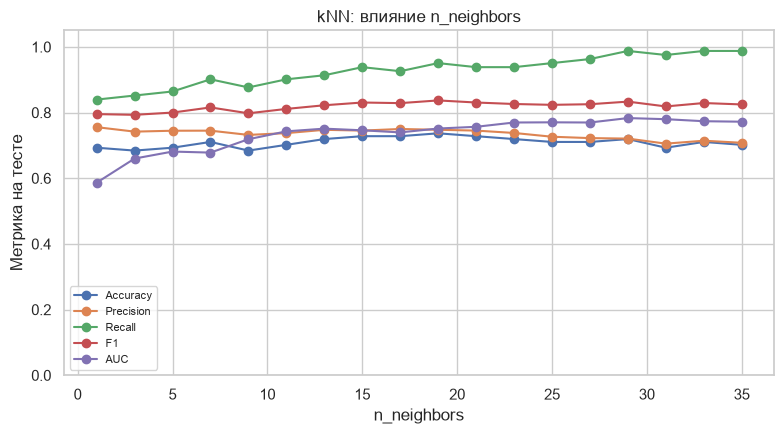


Результаты перебора n_neighbors:
 n_neighbors Accuracy Precision Recall    F1   AUC CV AUC
           1    0.693     0.756  0.840 0.795 0.586  0.599
           3    0.684     0.742  0.852 0.793 0.660  0.626
           5    0.693     0.745  0.864 0.800 0.681  0.629
           7    0.711     0.745  0.901 0.816 0.678  0.626
           9    0.684     0.732  0.877 0.798 0.719  0.629
          11    0.702     0.737  0.901 0.811 0.743  0.657
          13    0.719     0.747  0.914 0.822 0.751  0.681
          15    0.728     0.745  0.938 0.831 0.746  0.685
          17    0.728     0.750  0.926 0.829 0.740  0.680
          19    0.737     0.748  0.951 0.837 0.751  0.675
          21    0.728     0.745  0.938 0.831 0.757  0.673
          23    0.719     0.738  0.938 0.826 0.770  0.675
          25    0.711     0.726  0.951 0.824 0.770  0.672
          27    0.711     0.722  0.963 0.825 0.770  0.677
          29    0.719     0.721  0.988 0.833 0.783  0.689
          31    0.693     0.705  0.975

Accuracy,Precision,Recall,F1,AUC,Specificity,Balanced Accuracy,Train Accuracy,CV AUC (best)
0.719,0.733,0.951,0.828,0.764,0.152,0.551,1.000,0.697


In [73]:
_ = sweep_and_plot(
    'kNN',
    values=list(range(1, 36, 2)),
    factory=lambda v: KNeighborsClassifier(n_neighbors=v),
    scaling='standard',
    param_label='n_neighbors',
)

gs_knn = run_grid(
    'kNN',
    make_pipeline(KNeighborsClassifier(), 'standard'),
    {
        'classifier__n_neighbors': [1, 3, 5, 7, 9, 11, 15, 21, 31],
        'classifier__weights': ['uniform', 'distance'],
        'classifier__metric': ['euclidean', 'manhattan', 'chebyshev'],
    }
)


### Итоговая таблица

In [74]:
import pandas as pd
import numpy as np

def clean_params(params):
    """Очищает параметры от системных оберток numpy для читаемого вывода"""
    clean = {}
    for k, v in params.items():
        if isinstance(v, np.ndarray):
            clean[k] = v.tolist()
        elif isinstance(v, (np.floating, np.integer)):
            clean[k] = v.item()
        else:
            clean[k] = v
    return clean

# 1. Собираем словарь с лучшими параметрами
best_params_dict = {
    rec['Модель']: str(clean_params(rec['Лучшие параметры'])) 
    for rec in search_summaries
}

# 2. Формируем данные для итоговой таблицы
cmp_rows = []
for name in tuned_df.index:
    base_name = 'SVM (RBF)' if name == 'SVM' else name
    
    # Получаем метрики лучшей модели
    tuned_metrics = tuned_df.loc[name]
    # Получаем метрики базовой модели (если есть)
    base_metrics = baseline_df.loc[base_name] if base_name in baseline_df.index else pd.Series(dtype=float)
    
    # --- Извлекаем нужные метрики для лучшей модели ---
    # Обратите внимание: в вашем коде колонки могут называться 'F1' и 'AUC', 
    # а на скриншоте 'F1-score' и 'ROC-AUC'. Мы зададим им красивые имена ниже.
    t_cv = tuned_metrics.get('CV AUC (best)', tuned_metrics.get('CV AUC', np.nan)) # или CV F1-score, если он есть
    t_acc = tuned_metrics.get('Accuracy', np.nan)
    t_prec = tuned_metrics.get('Precision', np.nan)
    t_rec = tuned_metrics.get('Recall', np.nan)
    t_f1 = tuned_metrics.get('F1', np.nan)
    t_auc = tuned_metrics.get('AUC', np.nan)
    
    # --- Извлекаем метрики базовой модели для расчета дельты ---
    b_acc = base_metrics.get('Accuracy', np.nan)
    b_prec = base_metrics.get('Precision', np.nan)
    b_rec = base_metrics.get('Recall', np.nan)
    b_f1 = base_metrics.get('F1', np.nan)
    b_auc = base_metrics.get('AUC', np.nan)
    
    # Собираем строку. Сначала блок "Лучшие метрики", затем блок "Изменение (Δ)"
    row = {
        'Модель': name,
        'Лучшие параметры': best_params_dict.get(name, '-'),
        
        # БЛОК 1: Лучшие метрики (как на скриншоте)
        ('CV (AUC/F1)'): t_cv, 
        ( 'Accuracy'): t_acc,
        ( 'Precision'): t_prec,
        ( 'Recall'): t_rec,
        ( 'F1-score'): t_f1,
        ( 'ROC-AUC'): t_auc,
        
        # БЛОК 2: Насколько изменились метрики (по сравнению с базовой)
        ('Изменение Accuracy'): t_acc - b_acc,
        ('Изменение Precision'): t_prec - b_prec,
        ('Изменение Recall'): t_rec - b_rec,
        ('Изменение F1-score'): t_f1 - b_f1,
        ('Изменение ROC-AUC'): t_auc - b_auc,
    }
    cmp_rows.append(row)

# 3. Создаем DataFrame
summary_df = pd.DataFrame(cmp_rows).set_index('Модель')

# Сортируем модели по убыванию ROC-AUC лучшей модели
summary_df = summary_df.sort_values(('ROC-AUC'), ascending=False)


# 4. Красивый вывод (форматируем числа до 3 знаков)
styled_summary = summary_df.style.format(
    {col: "{:.3f}" for col in summary_df.columns if col != 'Лучшие параметры'},
    na_rep='-'
)

# Подсвечиваем только блок с изменениями (Δ)
# Если дельта положительная (модель стала лучше) — зеленеет, если отрицательная — краснеет
delta_cols = [col for col in summary_df.columns if col[0] == 'Изменение (Δ)']
for col in delta_cols:
    styled_summary = styled_summary.background_gradient(
        subset=[col], cmap='RdYlGn', vmin=-0.15, vmax=0.15
    )

# Убираем ограничение на ширину столбца, чтобы параметры было видно полностью
pd.set_option('display.max_colwidth', None)

display(styled_summary)

,Лучшие параметры,CV (AUC/F1),Accuracy,Precision,Recall,F1-score,ROC-AUC,Изменение Accuracy,Изменение Precision,Изменение Recall,Изменение F1-score,Изменение ROC-AUC
Модель,,,,,,,,,,,,
MultinomialNB,"{'classifier__alpha': 0.01, 'classifier__fit_prior': True}",0.710,0.711,0.711,1.000,0.831,0.819,0.000,0.000,0.000,0.000,0.014
ComplementNB,"{'classifier__alpha': 0.01, 'classifier__fit_prior': True, 'classifier__norm': False}",0.710,0.702,0.943,0.617,0.746,0.819,0.009,-0.017,0.025,0.013,0.014
SVM,"{'classifier__C': 0.1, 'classifier__class_weight': 'balanced', 'classifier__gamma': 'scale', 'classifier__kernel': 'linear'}",0.732,0.719,0.980,0.617,0.758,0.816,0.009,0.270,-0.383,-0.073,0.162
GaussianNB,{'classifier__var_smoothing': 0.01},0.715,0.588,1.000,0.420,0.591,0.814,-0.018,0.000,-0.025,-0.024,0.005
BernoulliNB,"{'classifier__alpha': 1.0, 'classifier__binarize': 0.0, 'classifier__fit_prior': True}",0.707,0.719,0.818,0.778,0.797,0.798,0.000,0.000,0.000,0.000,0.000
LDA,"{'classifier__priors': [0.5, 0.5], 'classifier__shrinkage': 'auto', 'classifier__solver': 'lsqr'}",0.702,0.719,0.902,0.679,0.775,0.783,0.018,0.182,-0.272,-0.045,0.018
kNN,"{'classifier__metric': 'manhattan', 'classifier__n_neighbors': 31, 'classifier__weights': 'distance'}",0.697,0.719,0.733,0.951,0.828,0.764,0.026,-0.011,0.086,0.028,0.083
Decision Tree,"{'classifier__ccp_alpha': 0.0, 'classifier__class_weight': 'balanced', 'classifier__criterion': 'entropy', 'classifier__max_depth': 4, 'classifier__min_samples_leaf': 20}",0.705,0.684,0.869,0.654,0.746,0.740,0.061,0.125,-0.062,0.017,0.185


## Нейронная сеть на TensorFlow

## Сравнительный анализ

### Таблица сравнения метрик качества для всех рассмотренных методов классификации

## Заключение